<a href="https://colab.research.google.com/github/zeeshansafdar752/Research_Paper/blob/main/ResearchPaper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1 Import Libraries

2 Load Dataset

3 Check Dataset

4 Clean Data

5 Define Target

6 Train / Validation / Test Split

7 Preprocessing

8 Baseline Model (Random Forest)

9 Choose Algorithm

10 Define Loss, Activation Function aur Optimizer

11 Training Loop (validation, early stopping)

12 Check Training Output (learning curves)

13 Model Evaluation (test set par, confusion matrix)

14 Error Analysis

15 Repeat with Multiple Seeds

16 Save Model


**# Import Libraries**

In [10]:
# Import Libraries
import os, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import zipfile
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import glob
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, roc_auc_score)
from sklearn.preprocessing import OneHotEncoder

**Select Device CPU or GPU**

In [11]:
SEED = 42
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


**# Drive mount**

In [14]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
import glob
hits = glob.glob("/content/drive/MyDrive/Colab Notebooks/xfl/train_test_network.csv", recursive=True)
print("found:", hits)
DATA_PATH = hits[0]
df = pd.read_csv(DATA_PATH, low_memory=False)
print(df.shape)

found: ['/content/drive/MyDrive/Colab Notebooks/xfl/train_test_network.csv']
(211043, 44)


In [17]:
df.head()

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


**Load Dataset**

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_ip                  211043 non-null  object 
 1   src_port                211043 non-null  int64  
 2   dst_ip                  211043 non-null  object 
 3   dst_port                211043 non-null  int64  
 4   proto                   211043 non-null  object 
 5   service                 211043 non-null  object 
 6   duration                211043 non-null  float64
 7   src_bytes               211043 non-null  int64  
 8   dst_bytes               211043 non-null  int64  
 9   conn_state              211043 non-null  object 
 10  missed_bytes            211043 non-null  int64  
 11  src_pkts                211043 non-null  int64  
 12  src_ip_bytes            211043 non-null  int64  
 13  dst_pkts                211043 non-null  int64  
 14  dst_ip_bytes        

In [19]:
print("missing values:", df.isna().sum().sum())
print("duplicate rows:", df.duplicated().sum())

# The loaded CSV file only contains traffic features.
# Since we loaded 'benign_traffic.csv', we can define 'label' as 0 (benign) and 'type' as 'benign'.
if "label" not in df.columns:
    df["label"] = 0
if "type" not in df.columns:
    df["type"] = "benign"

print("\n--- Label Distributions ---")
print(df["type"].value_counts())
print(df["label"].value_counts())

missing values: 0
duplicate rows: 20569

--- Label Distributions ---
type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
scanning      20000
ransomware    20000
xss           20000
mitm           1043
Name: count, dtype: int64
label
1    161043
0     50000
Name: count, dtype: int64


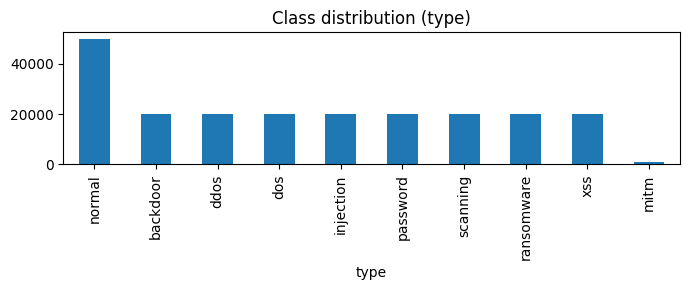

In [20]:
df["type"].value_counts().plot(kind="bar", figsize=(7, 3), title="Class distribution (type)")
plt.tight_layout(); plt.show()

**Cleen Data**

In [21]:
df = df.drop_duplicates().reset_index(drop=True)
df = df.replace("-", np.nan).replace([np.inf, -np.inf], np.nan)
# columns that only looked like text because of "-" become numbers again
for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]) and c != "type":
        converted = pd.to_numeric(df[c], errors="coerce")
        if converted.notna().sum() >= 0.9 * df[c].notna().sum():
            df[c] = converted

In [22]:
id_cols = ["ts", "src_ip", "dst_ip", "src_port", "dst_port"]
df = df.drop(columns=[c for c in id_cols if c in df.columns])

# text columns with too many different values (dns_query, http_uri, ...) are not useful as numbers
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 50 and c != "type"]
print("dropping text columns:", text_cols)
df = df.drop(columns=text_cols)
print(df.shape)

dropping text columns: ['dns_query', 'http_uri']
(190474, 38)


**Define Targets**

In [23]:
y_text = df["type"]
X = df.drop(columns=["type", "label"], errors="ignore")

le = LabelEncoder()
y = le.fit_transform(y_text)
class_names = list(le.classes_)
print(class_names)

cat_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
num_cols = [c for c in X.columns if c not in cat_cols]
print("categorical:", cat_cols)
print("numeric:", len(num_cols))

['backdoor', 'ddos', 'dos', 'injection', 'mitm', 'normal', 'password', 'ransomware', 'scanning', 'xss']
categorical: ['proto', 'service', 'conn_state', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_method', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_notice']
numeric: 17


**Split data into==> Test-->Train and validaction**

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, stratify=y_train, random_state=SEED)
print(len(X_train), len(X_val), len(X_test))

133331 19048 38095


**Data Preprocessing**

In [25]:
def transform(part, med, log_cols, scaler, enc):
    part = part.copy()
    part[num_cols] = part[num_cols].fillna(med)
    part[log_cols] = np.log1p(part[log_cols].clip(lower=0))
    out = scaler.transform(part[num_cols])
    if enc is not None:
        out = np.hstack([out, enc.transform(part[cat_cols].fillna("missing").astype(str))])
    return np.clip(out.astype("float32"), -10, 10)

def preprocess(X_train, X_val, X_test):
    med = X_train[num_cols].median()
    # decided on the train set only: never negative and large values
    log_cols = [c for c in num_cols if X_train[c].min() >= 0 and X_train[c].max() > 100]
    t = X_train.copy()
    t[num_cols] = t[num_cols].fillna(med)
    t[log_cols] = np.log1p(t[log_cols].clip(lower=0))
    scaler = StandardScaler().fit(t[num_cols])
    enc = None
    if cat_cols:
        enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        enc.fit(X_train[cat_cols].fillna("missing").astype(str))
    arrays = [transform(p, med, log_cols, scaler, enc) for p in (X_train, X_val, X_test)]
    assert all(not np.isnan(a).any() for a in arrays), "NaN left after preprocessing"
    return arrays[0], arrays[1], arrays[2], enc, scaler, med, log_cols

Xtr, Xva, Xte, enc, scaler, med, log_cols = preprocess(X_train, X_val, X_test)
print(Xtr.shape, len(log_cols), "log columns")

(133331, 135) 13 log columns


In [26]:
# class weights from the train set (the classes are not perfectly balanced)
counts = np.bincount(y_train, minlength=len(class_names))
class_weights = torch.tensor(counts.sum() / (len(class_names) * np.maximum(counts, 1)), dtype=torch.float32)
print(class_weights)

tensor([ 1.0179,  0.9527,  1.0029,  0.9541, 18.2896,  0.4531,  0.9590,  1.2927,
         0.9524,  1.2583])


**BaseLine Model (Random Forest)**

In [27]:
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)
rf.fit(Xtr, y_train)
rf_pred = rf.predict(Xva)
print("RF validation macro-F1:", round(f1_score(y_val, rf_pred, average="macro"), 4))

RF validation macro-F1: 0.9513


**DataLoaders**

In [28]:
BATCH = 256
def make_loader(X, y, shuffle):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y).long())
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle)

train_loader = make_loader(Xtr, y_train, True)
val_loader = make_loader(Xva, y_val, False)
test_loader = make_loader(Xte, y_test, False)

**CNN-LSTM**

In [29]:
class CNNLSTM(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(1, 32, 3, padding=1), nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 32, 3, padding=1), nn.BatchNorm1d(32), nn.ReLU(),
            nn.MaxPool1d(2))
        self.lstm = nn.LSTM(32, 64, batch_first=True)
        self.drop = nn.Dropout(0.2)
        self.fc = nn.Linear(128, n_classes)

    def forward(self, x):
        x = self.conv(x.unsqueeze(1))        # (batch, 32, n_features/2)
        x = x.transpose(1, 2)                # (batch, steps, 32)
        out, _ = self.lstm(x)                # LSTM output at every step
        z = torch.cat([out.mean(1), out.max(1).values], dim=1)   # average and max over all steps
        return self.fc(self.drop(z))

set_seed(SEED)
model = CNNLSTM(Xtr.shape[1], len(class_names)).to(device)
print(model)
print("parameters:", sum(p.numel() for p in model.parameters()))

CNNLSTM(
  (conv): Sequential(
    (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (lstm): LSTM(32, 64, batch_first=True)
  (drop): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=10, bias=True)
)
parameters: 29738


**Define Loss, Activation Funcation and Optimizer**

In [30]:
loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))
# the optimizer (Adam) and the learning-rate scheduler are created inside train_model() in the next step

**Traning Loop**

In [31]:
def predict(model, loader):
    model.eval()
    preds, probs = [], []
    with torch.no_grad():
        for xb, _ in loader:
            out = model(xb.to(device))
            probs.append(torch.softmax(out, 1).cpu().numpy())
            preds.append(out.argmax(1).cpu().numpy())
    return np.concatenate(preds), np.concatenate(probs)

In [32]:
def train_model(model, train_loader, val_loader, y_val, epochs=40, patience=6, save_path="best_model.pt", verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
    history = {"train_loss": [], "val_f1": []}
    best_f1, bad_epochs = 0, 0
    for epoch in range(epochs):
        model.train()
        total = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
        train_loss = total / len(train_loader.dataset)
        val_pred, _ = predict(model, val_loader)
        val_f1 = f1_score(y_val, val_pred, average="macro")
        sched.step(val_f1)
        history["train_loss"].append(train_loss); history["val_f1"].append(val_f1)
        if verbose:
            print(f"epoch {epoch+1:2d}  train loss {train_loss:.4f}  val macro-F1 {val_f1:.4f}")
        if val_f1 > best_f1:                 # early stopping: keep the best model
            best_f1, bad_epochs = val_f1, 0
            torch.save(model.state_dict(), save_path)
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print("early stopping at epoch", epoch + 1)
                break
    model.load_state_dict(torch.load(save_path, map_location=device))
    return history

In [33]:
history = train_model(model, train_loader, val_loader, y_val)

epoch  1  train loss 1.1909  val macro-F1 0.7388
epoch  2  train loss 0.6850  val macro-F1 0.8039
epoch  3  train loss 0.4491  val macro-F1 0.8645
epoch  4  train loss 0.4020  val macro-F1 0.8641
epoch  5  train loss 0.3893  val macro-F1 0.8733
epoch  6  train loss 0.3332  val macro-F1 0.8919
epoch  7  train loss 0.2966  val macro-F1 0.8714
epoch  8  train loss 0.2827  val macro-F1 0.9086
epoch  9  train loss 0.2383  val macro-F1 0.8724
epoch 10  train loss 0.2353  val macro-F1 0.9021
epoch 11  train loss 0.2119  val macro-F1 0.9099
epoch 12  train loss 0.3393  val macro-F1 0.8922
epoch 13  train loss 0.2934  val macro-F1 0.8966
epoch 14  train loss 0.2499  val macro-F1 0.8995
epoch 15  train loss 0.3095  val macro-F1 0.7947
epoch 16  train loss 0.4782  val macro-F1 0.8669
epoch 17  train loss 0.2985  val macro-F1 0.9014
early stopping at epoch 17


Show Result in Graphas

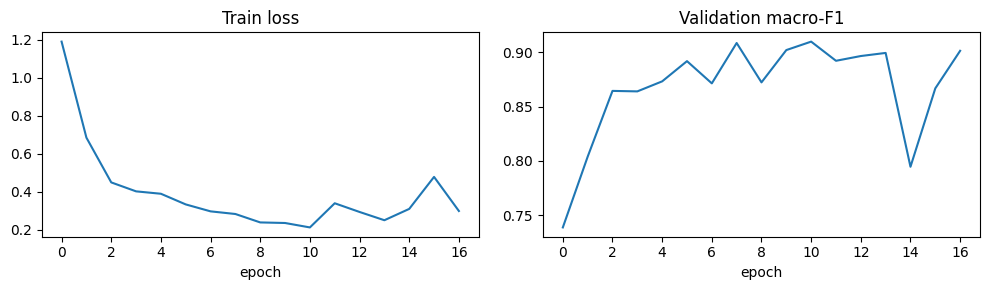

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(history["train_loss"]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(history["val_f1"]); ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

**Model Evaluation**

In [35]:
test_pred, test_prob = predict(model, test_loader)
acc = accuracy_score(y_test, test_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, test_pred, average="macro", zero_division=0)
print(f"accuracy {acc:.4f}  macro-P {p:.4f}  macro-R {r:.4f}  macro-F1 {f1:.4f}")
try:
    print("macro ROC-AUC:", round(roc_auc_score(y_test, test_prob, multi_class="ovr", average="macro"), 4))
except ValueError as e:
    print("ROC-AUC not computed:", e)
print(classification_report(y_test, test_pred, target_names=class_names, zero_division=0))

accuracy 0.9566  macro-P 0.8985  macro-R 0.9515  macro-F1 0.9122
macro ROC-AUC: 0.997
              precision    recall  f1-score   support

    backdoor       1.00      1.00      1.00      3742
        ddos       0.96      0.93      0.95      3999
         dos       0.98      0.96      0.97      3799
   injection       0.95      0.93      0.94      3993
        mitm       0.35      0.92      0.51       208
      normal       0.99      0.96      0.97      8408
    password       1.00      0.97      0.98      3972
  ransomware       0.91      0.96      0.93      2947
    scanning       0.97      0.99      0.98      4000
         xss       0.88      0.89      0.88      3027

    accuracy                           0.96     38095
   macro avg       0.90      0.95      0.91     38095
weighted avg       0.96      0.96      0.96     38095



**Classification report**

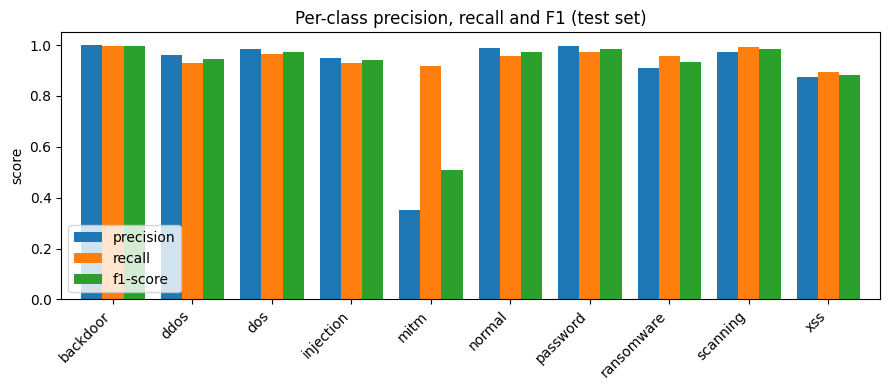

In [36]:
report = classification_report(y_test, test_pred, target_names=class_names, zero_division=0, output_dict=True)
rep = pd.DataFrame(report).T.loc[class_names, ["precision", "recall", "f1-score"]]

rep.plot(kind="bar", figsize=(9, 4), width=0.8)
plt.ylim(0, 1.05)
plt.title("Per-class precision, recall and F1 (test set)")
plt.ylabel("score")
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower left")
plt.tight_layout(); plt.show()

**confusion_matrix**

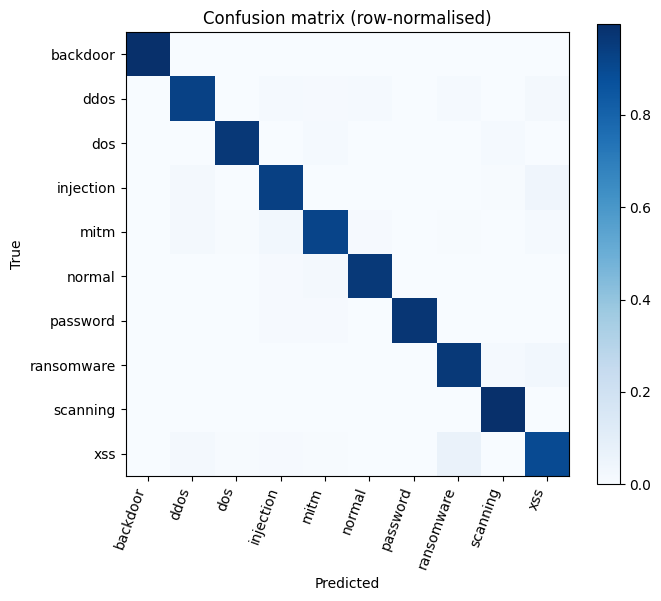

Random Forest test macro-F1: 0.9523
CNN-LSTM test macro-F1:      0.9122


In [37]:
cm = confusion_matrix(y_test, test_pred)
cm_norm = cm / cm.sum(1, keepdims=True)
plt.figure(figsize=(7, 6))
plt.imshow(cm_norm, cmap="Blues")
plt.xticks(range(len(class_names)), class_names, rotation=70, ha="right")
plt.yticks(range(len(class_names)), class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (row-normalised)")
plt.colorbar(); plt.tight_layout(); plt.show()

# baseline on the same test set
rf_test = rf.predict(Xte)
print("Random Forest test macro-F1:", round(f1_score(y_test, rf_test, average="macro"), 4))
print("CNN-LSTM test macro-F1:     ", round(f1, 4))